# Vaccination messaging: a reproducible multi-arm experiment analysis

**Question:** Do personalized high-risk messages improve recorded influenza vaccination, and do more detailed reasons add value?

This notebook contains all analysis code, tables, charts, and interpretation. It does not import project scripts or load precomputed results. The only required inputs are the two patient-level CSV files described in `data/README.md` in `data/raw/`. Outputs are saved in the notebook so readers can inspect the findings without running Python.

**Run it:** extract the project ZIP, install `requirements-notebook.txt`, open this notebook, and choose **Restart Kernel and Run All**. Use Python 3.12. Start Jupyter in either the project folder or its `notebooks` folder. The publication package requires obtaining the source data first; the complete working package already includes them. No network access is needed for the analysis after dependencies are installed.

**Scope:** secondary analysis of an existing study, NCT05009251, using the supplied manuscript release. The researchers conducted the trial. This portfolio analysis was developed after looking at the data and is not a new preregistration.

### Roadmap
1. Data provenance, variable definitions, and integrity checks
2. Enrollment, exclusions, missingness, and observed vaccination rates
3. Baseline balance and exploratory comparisons
4. Source-aligned models, risk adjustment, and sensitivity checks
5. Randomized one-versus-three reasons analysis
6. Interpretation, limitations, and reproducible exports

## 1. Setup and data provenance

The archive contains a manuscript release and a separate 2024 registry release. We use the manuscript's analysis and full-enrollment CSVs consistently; they are not merged with the registry data.

The source dictionary, R script, plan, and appendix are described in `references/SOURCES.md`. The complete working package retains those materials; the publication package links to the sources. Previous project work verified the design against them. Patients were randomized individually within two risk strata. Reasons count was randomized within risk/message strata in the two explanations arms. Risk level, outreach channels, and operational SMS timing should not be treated as independently randomized treatments.

The plan specifies a primary cutoff of November 5, 2021; patient-level dates are not released, so endpoint coding cannot be reconstructed from dates here. This notebook analyzes the supplied binary outcomes.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
from scipy.stats import norm
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# Search upward from the working directory; no machine-specific path is needed.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if
             (p / "data/raw/study_2_analysis_data_deid.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the complete project and start Jupyter in its project or notebooks folder.")
RAW = ROOT / "data/raw"
OUT = ROOT / "reports/notebook"
OUT.mkdir(parents=True, exist_ok=True)

ARMS = ["nocontact", "control", "unspecified", "medrec", "algorithm"]
LABELS = ["Passive control", "Active control", "High risk only",
          "Medical records + reasons", "Algorithm + reasons"]
HIGH = ["unspecified", "medrec", "algorithm"]
pd.set_option("display.max_columns", 12)

analysis = pd.read_csv(RAW / "study_2_analysis_data_deid.csv")
enrolled = pd.read_csv(RAW / "study_2_fulldata_deid.csv")
display(pd.DataFrame({"dataset": ["Enrolled", "Analysis"],
                      "patients": [len(enrolled), len(analysis)],
                      "variables": [enrolled.shape[1], analysis.shape[1]]}))

,dataset,patients,variables
0,Enrolled,45061,13
1,Analysis,42481,16


### Variables and treatment groups

| Role | Variables | Interpretation |
|---|---|---|
| Identifier | `s_ID` | Randomly generated patient ID |
| Treatment | `algo_condition` | `nocontact`: passive; `control`: reminder; `unspecified`: high risk only; `medrec`: medical-record explanation + reasons; `algorithm`: algorithm explanation + reasons |
| Risk stratum | `risk_condition` | `top3`: top 3%; `top10`: next 7% (top 4–10%), not all top-10% patients |
| Randomized reasons count | `num_reasons` | One or three reasons, applicable only within `medrec` and `algorithm` |
| Demographics | `sex`, `race`, `ethnicity`, `age65plus`, `age_bin` | EHR categories; age is grouped |
| Outreach | `modalities`, `sms_date_bin` | Available/sent channels and operational timing; not randomized factors |
| Other descriptors | `dup_address`, `geis_pcp` | Shared address; Geisinger primary-care provider |
| Primary endpoint | `vaccinated` | Recorded vaccination in the primary window |
| Additional endpoint | `vaccinated_4weeks` | Enrollment day and following four weeks (29 days) |
| Outcome source | `vax_source` | EHR or non-EHR source for recorded vaccinations |

The enrolled file additionally has original outreach eligibility, channel flags, and `exclude_reason`. In passive control, channel indicators describe eligibility rather than actual contact. A missing reasons count in a control arm is expected, not a reason to discard that patient.

In [2]:
# Check the structure and agreement of the two released populations.
assert analysis.s_ID.is_unique and enrolled.s_ID.is_unique
assert set(analysis.algo_condition) == set(ARMS)
for outcome in ["vaccinated", "vaccinated_4weeks"]:
    assert analysis[outcome].isin([0, 1]).all()
assert enrolled.vaccinated.isin([0, 1]).all()
included = enrolled.loc[enrolled.exclude_reason.isna()]
assert set(analysis.s_ID) == set(included.s_ID)
matched = analysis.merge(included, on="s_ID", suffixes=("_analysis", "_full"),
                         validate="one_to_one")
for variable in ["algo_condition", "vaccinated", "risk_condition"]:
    assert matched[f"{variable}_analysis"].eq(matched[f"{variable}_full"]).all()
assert (analysis.vaccinated_4weeks <= analysis.vaccinated).all()
assert ((analysis.vaccinated == 0) == analysis.vax_source.isna()).all()
print("Integrity checks passed: IDs, inclusion flags, assignments, risk strata, and outcomes agree.")

inventory = pd.DataFrame({"variable": analysis.columns,
                          "type": analysis.dtypes.astype(str).values,
                          "unique_nonmissing": analysis.nunique().values,
                          "missing": analysis.isna().sum().values})
display(inventory)

Integrity checks passed: IDs, inclusion flags, assignments, risk strata, and outcomes agree.


,variable,type,unique_nonmissing,missing
0,s_ID,object,42481,0
1,sex,object,2,0
2,race,object,6,0
3,ethnicity,object,3,0
4,age65plus,object,2,0
5,age_bin,object,6,0
6,modalities,object,6,0
7,sms_date_bin,object,2,21163
8,risk_condition,object,2,0
9,algo_condition,object,5,0


## 2. Enrollment, exclusions, and initial EDA

The source reports 45,164 randomized patients. Of these, 103 died before enrollment and are absent from the full-enrollment file. Another 2,580 enrolled patients were excluded from the manuscript analysis. These two groups must not be conflated.

We describe the retained analysis population first, then test sensitivity to alternative populations. This is not unrestricted intention-to-treat analysis of all randomized patients.

In [3]:
flow = pd.crosstab(enrolled.algo_condition,
                  enrolled.exclude_reason.fillna("included")).reindex(ARMS)
flow["enrolled"] = flow.sum(axis=1)
flow["excluded_pct"] = 100 * (flow.enrolled - flow.included) / flow.enrolled
display(flow.round(2))

missingness = analysis.isna().agg(["sum", "mean"]).T.rename(
    columns={"sum": "missing_n", "mean": "missing_fraction"})
display(missingness.loc[missingness.missing_n > 0])

cohort = pd.concat({column: analysis[column].value_counts(dropna=False)
                    for column in ["sex", "age65plus", "risk_condition", "dup_address"]},
                   names=["variable", "category"]).rename("patients")
display(cohort.to_frame())

exclude_reason,contra,dieddu,earlyvax,included,negreasons,enrolled,excluded_pct
algo_condition,,,,,,,
nocontact,100,25,247,8466,179,9017,6.11
control,105,22,215,8522,149,9013,5.45
unspecified,119,24,209,8498,161,9011,5.69
medrec,120,19,224,8470,170,9003,5.92
algorithm,119,15,201,8525,157,9017,5.46


,missing_n,missing_fraction
sms_date_bin,21163.0,0.498176
num_reasons,25486.0,0.599939
vax_source,28318.0,0.666604


patients
variable       category          
sex            Female       28766
               Male         13715
age65plus      <65          28699
               65+          13782
risk_condition top10        29668
               top3         12813
dup_address    0            35001
               1             7480

**Reading the audit:** `earlyvax` denotes early vaccination; `negreasons` denotes protective risk reasons; `contra` denotes contraindication; `dieddu` denotes death during study. Missingness in `num_reasons` is structural outside the reasons arms. Timing is not applicable to every patient. Missing vaccination source exactly corresponds to no recorded primary-window vaccination. No missing binary outcomes in the supplied file does not prove complete capture of vaccinations outside its records.

### Observed rates and confidence intervals

Wilson 95% intervals describe uncertainty in each arm's rate. Separate rate intervals are not confidence intervals for the differences between arms.

,n,vaccinated,rate,ci_low,ci_high,rate_pct,ci_low_pct,ci_high_pct
algo_condition,,,,,,,,
nocontact,8466,2668,0.315,0.305,0.325,31.514,30.533,32.512
control,8522,2807,0.329,0.319,0.339,32.938,31.948,33.944
unspecified,8498,2938,0.346,0.336,0.356,34.573,33.569,35.591
medrec,8470,2887,0.341,0.331,0.351,34.085,33.083,35.101
algorithm,8525,2863,0.336,0.326,0.346,33.584,32.589,34.593


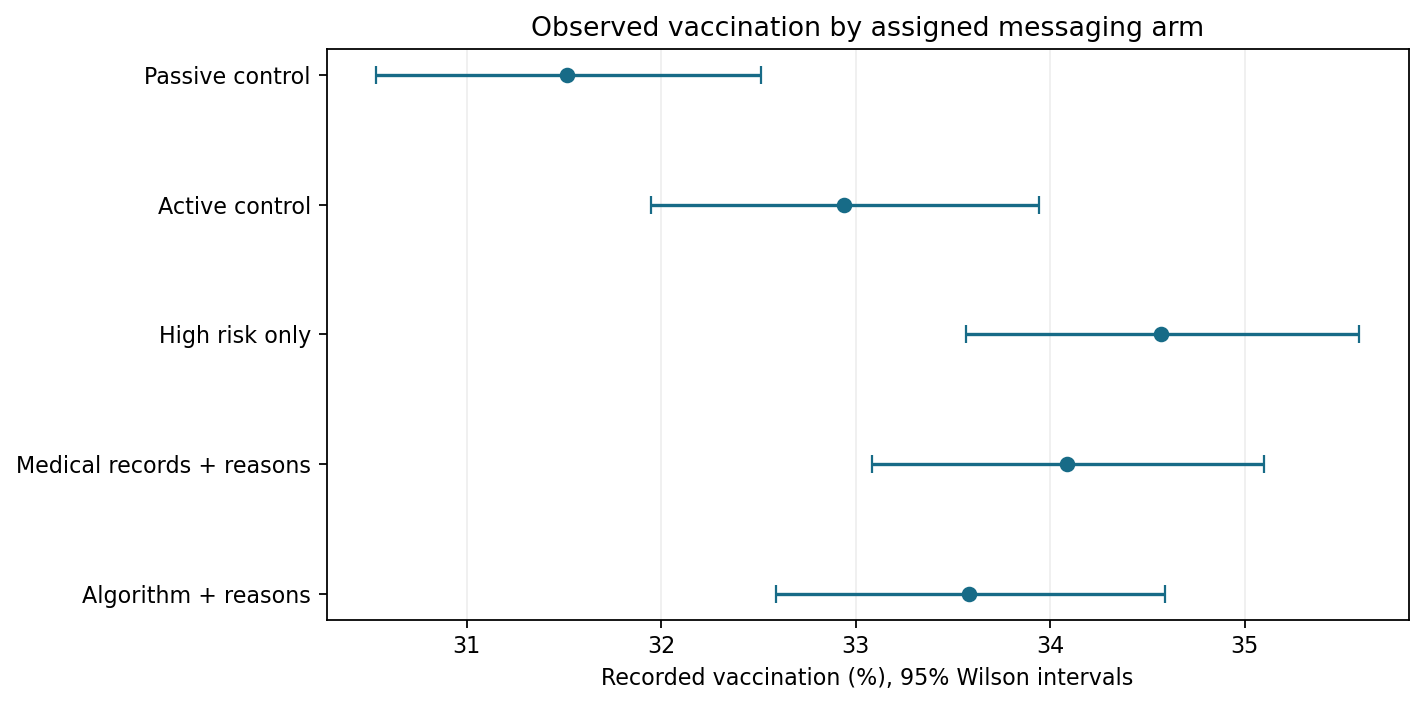

In [4]:
rates = analysis.groupby("algo_condition").vaccinated.agg(
    n="size", vaccinated="sum", rate="mean").reindex(ARMS)
rates["ci_low"], rates["ci_high"] = proportion_confint(
    rates.vaccinated, rates.n, method="wilson")
display(rates.assign(rate_pct=100*rates.rate,
                     ci_low_pct=100*rates.ci_low,
                     ci_high_pct=100*rates.ci_high).round(3))

def show_figure(fig, filename):
    """Embed an image in the notebook and save the same figure for reuse."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=160, bbox_inches="tight")
    (OUT / filename).write_bytes(buffer.getvalue())
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(100*rates.rate, range(5),
            xerr=100*np.vstack([rates.rate-rates.ci_low, rates.ci_high-rates.rate]),
            fmt="o", capsize=4, color="#176B87")
ax.set_yticks(range(5), LABELS)
ax.invert_yaxis()
ax.set_xlabel("Recorded vaccination (%), 95% Wilson intervals")
ax.set_title("Observed vaccination by assigned messaging arm")
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
show_figure(fig, "vaccination_rates.png")

The highest observed rate is in the high-risk-only arm. That ranking alone does not establish superiority. We need contrasts and their uncertainty rather than choosing the largest observed percentage.

## 3. Baseline balance and exploratory comparisons

For categorical characteristics we compare each level as a binary indicator. The standardized mean difference is the difference in proportions divided by the square root of the average Bernoulli variance. We summarize the largest absolute difference across all ten arm pairs. These descriptive checks do not prove balance in unmeasured variables or validate randomization by themselves.

In [5]:
def balance(df, variables, population):
    rows=[]
    for var in variables:
        for level in sorted(df[var].fillna('(missing)').astype(str).unique()):
            indicator=(df[var].fillna('(missing)').astype(str)==level)
            proportions=indicator.groupby(df.algo_condition).mean().reindex(ARMS)
            for i,left in enumerate(ARMS):
                for right in ARMS[i+1:]:
                    p,q=proportions[left],proportions[right]
                    denom=np.sqrt((p*(1-p)+q*(1-q))/2)
                    smd=(p-q)/denom if denom else (0 if p==q else np.nan)
                    rows.append(dict(population=population,variable=var,level=level,
                                     arm_left=left,arm_right=right,p_left=p,p_right=q,smd=smd,abs_smd=abs(smd)))
    return pd.DataFrame(rows)

In [6]:
balance_pairs = pd.concat([
    balance(enrolled, ["sex", "race", "ethnicity", "risk_condition", "modalities_orig"], "enrolled"),
    balance(analysis, ["sex", "race", "ethnicity", "risk_condition", "age_bin", "geis_pcp", "dup_address"], "analysis")
], ignore_index=True)
balance_summary = balance_pairs.groupby(["population", "variable"]).abs_smd.max().rename(
    "maximum_absolute_smd").to_frame()
display(balance_summary.round(4))

maximum_absolute_smd
population variable                             
analysis   age_bin                        0.0238
           dup_address                    0.0188
           ethnicity                      0.0191
           geis_pcp                       0.0330
           race                           0.0422
           risk_condition                 0.0061
           sex                            0.0267
enrolled   ethnicity                      0.0176
           modalities_orig                0.0365
           race                           0.0373
           risk_condition                 0.0010
           sex                            0.0242

All checked differences are below .05 in this dataset. Age and PCP information are available only in the analysis file, so those checks concern the selected population. We do not use message delivery or reasons count as baseline characteristics across all five arms.

### Initial seven-comparison family

This reproduces the first exploratory pass: four individual arms versus passive control, algorithm versus medical-record framing, reasons arms versus high risk only, and pooled high risk versus active control. P-values use a pooled two-proportion z test; difference intervals use an unpooled large-sample standard error. Holm adjustment covers these seven tests. The intervals remain individual, not simultaneous.

In [7]:
def contrast(a, treatment, reference, name):
    t = a.loc[a.algo_condition.isin(treatment), 'vaccinated']
    c = a.loc[a.algo_condition.isin(reference), 'vaccinated']
    diff = t.mean() - c.mean()
    se = np.sqrt(t.mean()*(1-t.mean())/len(t) + c.mean()*(1-c.mean())/len(c))
    pooled = (t.sum()+c.sum())/(len(t)+len(c))
    null_se = np.sqrt(pooled*(1-pooled)*(1/len(t)+1/len(c)))
    return dict(contrast=name, n_treatment=len(t), n_reference=len(c),
                difference_pp=100*diff, ci_low_pp=100*(diff-1.96*se),
                ci_high_pp=100*(diff+1.96*se),
                relative_lift_pct=100*diff/c.mean(), p_value=2*norm.sf(abs(diff/null_se)))

In [8]:
exploratory_specs = [
    (HIGH, ["control"], "Pooled high risk vs active control"),
    (["medrec", "algorithm"], ["unspecified"], "Reasons arms vs high risk only"),
    (["algorithm"], ["medrec"], "Algorithm vs medical records")
] + [([arm], ["nocontact"], f"{arm} vs passive control") for arm in ARMS[1:]]
exploratory = pd.DataFrame([contrast(analysis, *spec) for spec in exploratory_specs])
exploratory["p_holm"] = multipletests(exploratory.p_value, method="holm")[1]
display(exploratory.round(5))

,contrast,n_treatment,n_reference,difference_pp,ci_low_pp,ci_high_pp,relative_lift_pct,p_value,p_holm
0,Pooled high risk vs active control,25493,8522,1.14167,-0.01344,2.29678,3.46608,0.05374,0.18829
1,Reasons arms vs high risk only,16995,8498,-0.73936,-1.97572,0.49700,-2.13856,0.24035,0.48071
2,Algorithm vs medical records,8525,8470,-0.50143,-1.92415,0.92129,-1.47111,0.48970,0.48970
3,control vs passive control,8522,8466,1.42398,0.01860,2.82937,4.51854,0.04707,0.18829
4,unspecified vs passive control,8498,8466,3.05855,1.64366,4.47344,9.70527,0.00002,0.00016
5,medrec vs passive control,8470,8466,2.57071,1.15708,3.98435,8.15729,0.00037,0.00220
6,algorithm vs passive control,8525,8466,2.06929,0.66057,3.47800,6.56618,0.00400,0.02000


## 4. Source-aligned model comparisons

We now reproduce four comparisons from the original analysis code. A linear probability model's treatment coefficient is an absolute difference in vaccination probability. HC1 standard errors allow unequal outcome variance across groups; we use a t reference distribution. This does not account for household clustering.

Both conventional OLS and HC1 results are retained. Conventional outputs were independently matched against R in earlier project validation. The helper below is fully defined here; nothing is imported from the project scripts.

The four tests form a separate family from the initial seven. The registered plan reported these confirmatory tests without multiplicity adjustment. Our additional Holm values are a conservative portfolio extension. No global error control is claimed across every table and sensitivity analysis.

In [9]:
def fit_contrast(df, outcome, treatment, reference, label, population, adjust_risk=False):
    d = df[df.algo_condition.isin(treatment+reference)].copy()
    assert d[outcome].notna().all() and d[outcome].isin([0,1]).all()
    x = d.algo_condition.isin(treatment).astype(float).rename('treatment')
    design = sm.add_constant(x)
    if adjust_risk:
        design['top3'] = (d.risk_condition == 'top3').astype(float)
    model = sm.OLS(d[outcome].astype(float), design).fit()
    # HC1 with t-based inference mirrors the source robustness approach.
    robust = model.get_robustcov_results(cov_type='HC1', use_t=True)
    raw_diff = d.loc[x==1,outcome].mean()-d.loc[x==0,outcome].mean()
    if not adjust_risk:
        assert np.isclose(model.params['treatment'],raw_diff,atol=1e-12)
    result = dict(population=population,outcome=outcome,contrast=label,n=len(d),
                  n_treatment=int(x.sum()),n_reference=int((x==0).sum()),
                  difference_pp=100*model.params['treatment'])
    for name, mod in [('ols',model),('hc1',robust)]:
        ci = np.asarray(mod.conf_int())[1]
        result.update({f'{name}_se_pp':100*np.asarray(mod.bse)[1],
                       f'{name}_ci_low_pp':100*ci[0],f'{name}_ci_high_pp':100*ci[1],
                       f'{name}_p':np.asarray(mod.pvalues)[1]})
    return result

In [10]:
SPECS = [
    ("1a_highrisk_vs_active", HIGH, ["control"]),
    ("1b_highrisk_vs_passive", HIGH, ["nocontact"]),
    ("2_reasons_vs_highrisk_only", ["medrec", "algorithm"], ["unspecified"]),
    ("3_active_vs_passive", ["control"], ["nocontact"])
]

def four_comparisons(data, population, outcome="vaccinated", adjust_risk=False):
    result = pd.DataFrame([
        fit_contrast(data, outcome, treatment, reference, label, population, adjust_risk)
        for label, treatment, reference in SPECS
    ])
    result["hc1_p_holm_within_family"] = multipletests(result.hc1_p, method="holm")[1]
    return result

main_models = four_comparisons(analysis, "analysis")
model_columns = ["contrast", "n", "difference_pp", "hc1_ci_low_pp", "hc1_ci_high_pp",
                 "hc1_p", "hc1_p_holm_within_family"]
display(main_models[model_columns].round(5))

,contrast,n,difference_pp,hc1_ci_low_pp,hc1_ci_high_pp,hc1_p,hc1_p_holm_within_family
0,1a_highrisk_vs_active,34015,1.14167,-0.01350,2.29683,0.05274,0.14121
1,1b_highrisk_vs_passive,33959,2.56565,1.41760,3.71370,0.00001,0.00005
2,2_reasons_vs_highrisk_only,25493,-0.73936,-1.97581,0.49709,0.24118,0.24118
3,3_active_vs_passive,16988,1.42398,0.01845,2.82952,0.04707,0.14121


Pooled high-risk messaging exceeds passive control by about 2.57 percentage points. Its roughly 1.14-point advantage over active control is less certain, with an interval crossing zero. The three high-risk arms are pooled using their observed sample sizes; this contrast does not isolate algorithm messaging.

### Risk adjustment, population selection, and the 29-day robustness endpoint

Risk adjustment adds the randomized risk-stratum indicator with a common treatment effect. Alternative populations exclude shared addresses, restore enrolled patients except contraindications, or restore all enrolled records. These target different populations. Restoring early vaccinations or patients who died changes interpretation; it does not recover all randomized patients. Removing shared-address patients is not a substitute for cluster-robust inference.

In [11]:
adjusted_models = four_comparisons(analysis, "analysis_risk_adjusted", adjust_risk=True)
populations = {
    "analysis": analysis,
    "analysis_no_shared_address": analysis.loc[analysis.dup_address == 0],
    "enrolled_excluding_contra": enrolled.loc[enrolled.exclude_reason.fillna("included") != "contra"],
    "all_enrolled": enrolled
}
sensitivity_models = pd.concat([
    four_comparisons(data, name) for name, data in populations.items()
], ignore_index=True)
four_week_models = four_comparisons(analysis, "analysis", "vaccinated_4weeks")

display(Markdown("**Risk-adjusted primary outcome**"))
display(adjusted_models[model_columns].round(5))
display(Markdown("**Population sensitivity: absolute differences in percentage points**"))
display(sensitivity_models.pivot(index="population", columns="contrast", values="difference_pp").round(3))
display(Markdown("**Four-week endpoint**"))
display(four_week_models[model_columns].round(5))

**Risk-adjusted primary outcome**

,contrast,n,difference_pp,hc1_ci_low_pp,hc1_ci_high_pp,hc1_p,hc1_p_holm_within_family
0,1a_highrisk_vs_active,34015,1.14872,-0.00549,2.30293,0.05110,0.14053
1,1b_highrisk_vs_passive,33959,2.57212,1.42456,3.71969,0.00001,0.00004
2,2_reasons_vs_highrisk_only,25493,-0.74176,-1.97781,0.49428,0.23951,0.23951
3,3_active_vs_passive,16988,1.42443,0.01989,2.82897,0.04684,0.14053


**Population sensitivity: absolute differences in percentage points**

contrast,1a_highrisk_vs_active,1b_highrisk_vs_passive,2_reasons_vs_highrisk_only,3_active_vs_passive
population,,,,
all_enrolled,1.175,2.475,-0.762,1.301
analysis,1.142,2.566,-0.739,1.424
analysis_no_shared_address,1.510,2.783,-0.658,1.273
enrolled_excluding_contra,1.216,2.538,-0.742,1.322


**Four-week endpoint**

,contrast,n,difference_pp,hc1_ci_low_pp,hc1_ci_high_pp,hc1_p,hc1_p_holm_within_family
0,1a_highrisk_vs_active,34015,0.19800,-0.78084,1.17685,0.69175,0.69175
1,1b_highrisk_vs_passive,33959,3.00800,2.06867,3.94734,0.00000,0.00000
2,2_reasons_vs_highrisk_only,25493,-1.02261,-2.07138,0.02616,0.05599,0.11199
3,3_active_vs_passive,16988,2.81000,1.64472,3.97528,0.00000,0.00001


The passive-control comparison remains positive in each checked population; the active-control contrast remains smaller and uncertain after within-family adjustment. Risk adjustment changes the main estimates little. The 29-day outcome was not preregistered and is distinct from the registered nine-week vaccination endpoint. Some Study 2 outreach occurred after day 29, so it does not capture the full intervention. It does not establish longer-term equivalence or explain a mechanism.

### Logistic-model sensitivity

As an additional check, fit unadjusted binomial logistic models for the same four primary comparisons. Odds ratios are not risk ratios or percentage-point differences. These models reuse the same data, so they are sensitivity checks rather than independent replications.

In [12]:
logistic_rows = []
for label, treatment, reference in SPECS:
    subset = analysis.loc[analysis.algo_condition.isin(treatment + reference)]
    design = sm.add_constant(subset.algo_condition.isin(treatment).astype(float).rename("treatment"))
    model = sm.GLM(subset.vaccinated, design, family=sm.families.Binomial()).fit()
    low, high = model.conf_int().loc["treatment"]
    logistic_rows.append({"contrast": label, "n": len(subset),
                          "odds_ratio": np.exp(model.params.treatment),
                          "or_ci_low": np.exp(low), "or_ci_high": np.exp(high),
                          "p_value": model.pvalues.treatment})
logistic_models = pd.DataFrame(logistic_rows)
logistic_models["p_holm"] = multipletests(logistic_models.p_value, method="holm")[1]
display(logistic_models.round(5))

,contrast,n,odds_ratio,or_ci_low,or_ci_high,p_value,p_holm
0,1a_highrisk_vs_active,34015,1.05258,0.99917,1.10884,0.05375,0.14126
1,1b_highrisk_vs_passive,33959,1.12350,1.06587,1.18425,0.00001,0.00006
2,2_reasons_vs_highrisk_only,25493,0.96768,0.91603,1.02224,0.24036,0.24036
3,3_active_vs_passive,16988,1.06738,1.00084,1.13834,0.04709,0.14126


## 5. Does giving three personalized reasons work better than giving one?

This factorial comparison applies only to the 16,995 analyzed patients in the medical-record and algorithm arms. It does not compare randomized reasons counts across all five messaging groups.

We use medical-record framing and one reason as reference categories. The model includes framing, reasons count, and their interaction. The interaction is **(three minus one in algorithm) minus (three minus one in medical records)**. It is not itself evidence that three reasons work in either arm.

In [13]:
reasons_data = analysis.loc[analysis.algo_condition.isin(["medrec", "algorithm"])]
reason_rates = reasons_data.groupby(["algo_condition", "num_reasons"]).vaccinated.agg(
    n="size", vaccinated="sum", rate="mean")
reason_rates["ci_low"], reason_rates["ci_high"] = proportion_confint(
    reason_rates.vaccinated, reason_rates.n, method="wilson")
display(reason_rates.assign(rate_pct=100*reason_rates.rate).round(4))

n  vaccinated    rate  ci_low  ci_high  \
algo_condition num_reasons                                              
algorithm      1reason      4326        1446  0.3343  0.3204   0.3485   
               3reasons     4199        1417  0.3375  0.3233   0.3519   
medrec         1reason      4318        1508  0.3492  0.3352   0.3636   
               3reasons     4152        1379  0.3321  0.3180   0.3466   

                            rate_pct  
algo_condition num_reasons            
algorithm      1reason       33.4258  
               3reasons      33.7461  
medrec         1reason       34.9236  
               3reasons      33.2129

In [14]:
def fit_reasons(data, outcome='vaccinated', adjust_risk=False):
    d=data[data.algo_condition.isin(['medrec','algorithm'])].copy()
    assert d.num_reasons.isin(['1reason','3reasons']).all()
    assert d[outcome].isin([0,1]).all() and d.s_ID.is_unique
    x=pd.DataFrame({'const':1.,'algorithm':(d.algo_condition=='algorithm').astype(float),
                    'three_reasons':(d.num_reasons=='3reasons').astype(float)},index=d.index)
    x['interaction']=x.algorithm*x.three_reasons
    if adjust_risk:
        x['top3']=(d.risk_condition=='top3').astype(float)
        x['algorithm_top3']=x.algorithm*x.top3
    model=sm.OLS(d[outcome].astype(float),x).fit()
    robust=model.get_robustcov_results(cov_type='HC1',use_t=True)
    contrasts={'Three vs one: medical records':[0,0,1,0],
               'Three vs one: algorithm':[0,0,1,1],
               'Interaction: algorithm minus medical records':[0,0,0,1],
               'Three vs one: equal-arm average':[0,0,1,.5]}
    rows=[]
    for label,vector in contrasts.items():
        vector=vector+[0]*(x.shape[1]-4)
        row={'contrast':label,'n':len(d)}
        for name,m in [('ols',model),('hc1',robust)]:
            test=m.t_test(vector)
            lo,hi=np.asarray(test.conf_int()).ravel()
            row.update({f'{name}_difference_pp':100*test.effect.item(),
                        f'{name}_se_pp':100*test.sd.item(),
                        f'{name}_ci_low_pp':100*lo,f'{name}_ci_high_pp':100*hi,
                        f'{name}_p':test.pvalue.item()})
        rows.append(row)
    result=pd.DataFrame(rows)
    result['hc1_p_holm_within_family']=multipletests(result.hc1_p,method='holm')[1]
    if not adjust_risk:
        means=d.groupby(['algo_condition','num_reasons'])[outcome].mean()
        med=means['medrec','3reasons']-means['medrec','1reason']
        alg=means['algorithm','3reasons']-means['algorithm','1reason']
        assert np.allclose(result.ols_difference_pp,[100*med,100*alg,100*(alg-med),50*(med+alg)],atol=1e-10)
    return result,model

,contrast,n,hc1_difference_pp,hc1_ci_low_pp,hc1_ci_high_pp,hc1_p,hc1_p_holm_within_family
0,Three vs one: medical records,16995,-1.71067,-3.72951,0.30817,0.09675,0.38701
1,Three vs one: algorithm,16995,0.32033,-1.68541,2.32607,0.75425,0.75425
2,Interaction: algorithm minus medical records,16995,2.03100,-0.81482,4.87682,0.16187,0.48560
3,Three vs one: equal-arm average,16995,-0.69517,-2.11808,0.72774,0.33827,0.67654


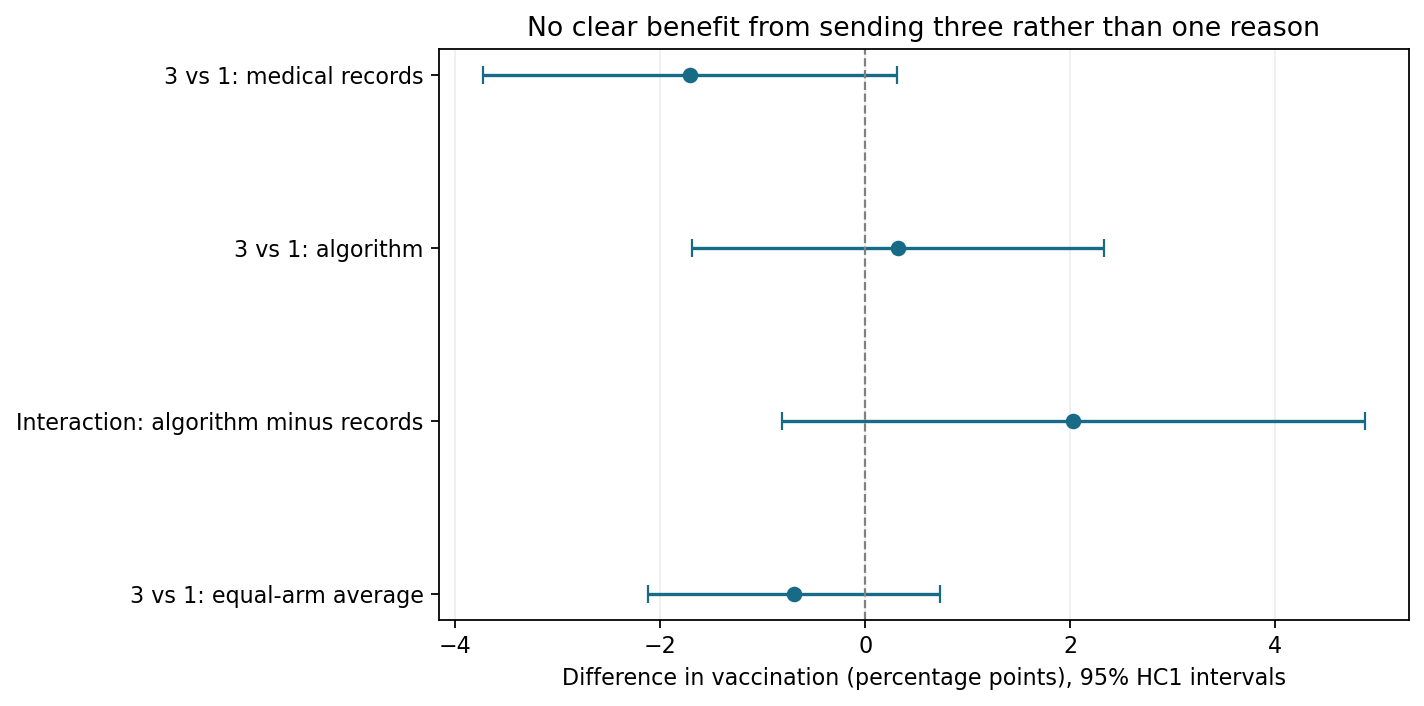

In [15]:
reasons_main, reasons_ols = fit_reasons(analysis)
reason_columns = ["contrast", "n", "hc1_difference_pp", "hc1_ci_low_pp", "hc1_ci_high_pp",
                  "hc1_p", "hc1_p_holm_within_family"]
display(reasons_main[reason_columns].round(5))

fig, ax = plt.subplots(figsize=(9, 4.5))
effect = reasons_main.hc1_difference_pp
ax.errorbar(effect, range(4),
            xerr=np.vstack([effect-reasons_main.hc1_ci_low_pp,
                            reasons_main.hc1_ci_high_pp-effect]),
            fmt="o", capsize=4, color="#176B87")
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(range(4), ["3 vs 1: medical records", "3 vs 1: algorithm",
                        "Interaction: algorithm minus records", "3 vs 1: equal-arm average"])
ax.invert_yaxis()
ax.set_xlabel("Difference in vaccination (percentage points), 95% HC1 intervals")
ax.set_title("No clear benefit from sending three rather than one reason")
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
show_figure(fig, "reasons_effects.png")

The average gives equal weight to the two messaging arms; uncertainty includes covariance between model terms. The estimated average difference is -0.70 points, with an interval from -2.12 to +0.73. The framing interaction is +2.03 points, with an interval from -0.81 to +4.88. Neither establishes a benefit or equivalence. The four related contrasts form one Holm family per population/endpoint; intervals are individual 95% intervals.

### Reasons-count exclusions and sensitivity

Because the analysis population was selected after randomization, inspect exclusions separately by randomized reasons assignment. Risk adjustment below includes distinct risk-stratum intercepts within each framing arm, assuming a common reasons effect across risk strata within that arm.

In [16]:
reasons_enrolled = enrolled.loc[enrolled.algo_condition.isin(["medrec", "algorithm"])].copy()
reasons_exclusions = pd.crosstab(
    [reasons_enrolled.algo_condition, reasons_enrolled.num_reasons, reasons_enrolled.risk_condition],
    reasons_enrolled.exclude_reason.fillna("included"))
reason_flow = reasons_exclusions.groupby(level=[0, 1]).sum()
reason_flow["enrolled"] = reason_flow.sum(axis=1)
reason_flow["excluded_pct"] = 100*(1-reason_flow.included/reason_flow.enrolled)
display(reason_flow.round(3))

reason_sensitivity_rows = []
reason_scenarios = [
    (name, data, "vaccinated", False) for name, data in populations.items()
] + [("analysis_risk_adjusted", analysis, "vaccinated", True),
     ("analysis", analysis, "vaccinated_4weeks", False)]
for population, data, outcome, adjust in reason_scenarios:
    result, _ = fit_reasons(data, outcome, adjust)
    result.insert(0, "outcome", outcome)
    result.insert(0, "population", population)
    reason_sensitivity_rows.append(result)
reason_sensitivity = pd.concat(reason_sensitivity_rows, ignore_index=True)
display(reason_sensitivity.loc[
    reason_sensitivity.contrast == "Three vs one: equal-arm average",
    ["population", "outcome"] + reason_columns[2:]
].round(4))

exclude_reason              contra  dieddu  earlyvax  included  negreasons  \
algo_condition num_reasons                                                   
algorithm      1reason          61       5       110      4326           9   
               3reasons         58      10        91      4199         148   
medrec         1reason          62      12       108      4318           5   
               3reasons         58       7       116      4152         165   

exclude_reason              enrolled  excluded_pct  
algo_condition num_reasons                          
algorithm      1reason          4511         4.101  
               3reasons         4506         6.813  
medrec         1reason          4505         4.151  
               3reasons         4498         7.692

,population,outcome,hc1_difference_pp,hc1_ci_low_pp,hc1_ci_high_pp,hc1_p,hc1_p_holm_within_family
3,analysis,vaccinated,-0.6952,-2.1181,0.7277,0.3383,0.6765
7,analysis_no_shared_address,vaccinated,-1.0053,-2.5769,0.5663,0.2099,0.8397
11,enrolled_excluding_contra,vaccinated,-0.4885,-1.8709,0.8940,0.4886,0.9772
15,all_enrolled,vaccinated,-0.5344,-1.9038,0.8349,0.4443,0.8886
19,analysis_risk_adjusted,vaccinated,-0.7278,-2.1501,0.6945,0.3159,0.6318
23,analysis,vaccinated_4weeks,-0.2638,-1.4597,0.9321,0.6655,1.0000


Exclusions were higher in three-reason groups: about 7.69% versus 4.15% in medical records and 6.81% versus 4.10% in algorithm. Restoring excluded patients still provides no clear evidence of a benefit, but it does not eliminate potential selection bias. The four-week result is similarly uncertain. The conventional interaction coefficients, standard errors, and p-values were independently matched against R; the optional validation files are included in the project.

## 6. Conclusions and limits

**Supported finding:** pooled high-risk messaging exceeds passive control by roughly 2.57 percentage points in the manuscript analysis population. Its advantage over a basic reminder is less certain. There is no clear incremental benefit from reasons-based messages or from three rather than one reason.

**What this does not establish:** that the highest observed arm is superior to every other arm; that messages are equivalent; that explanations never help; or that a particular psychological mechanism caused uptake.

Interpretation is limited by population exclusions, potential household dependence and spillovers, imperfect outcome capture, and the specific patient population. Household cluster identifiers and patient-level outcome dates are unavailable. There is no global multiplicity adjustment across all exploratory work. The notebook is a partial replication and extension, not a recreation of every published result.

### Attribution and source reconciliation

Original research and data: Gail M. Rosenbaum and colleagues, [DOI: 10.1038/s41562-026-02603-4](https://doi.org/10.1038/s41562-026-02603-4); [NCT05009251](https://clinicaltrials.gov/study/NCT05009251); [OSF](https://osf.io/mqbux/). The two CSV inputs come from the manuscript directory of the supplied archive. Sources, source formulas, and rights checks are documented in `references/SOURCES.md` and `THIRD_PARTY_NOTICES.md`.

The conventional main-model results match the PMC author manuscript after rounding. `reports/source_reconciliation.md` records a reasons-coefficient sign discrepancy, a printed degrees-of-freedom discrepancy, and the distinction between our equal-arm reasons average and the manuscript's reported reasons-count contrast. None is hidden by changing the input data or relabeling our estimand.

The Methods verify message components and delivery channels. Complete verbatim messages are referred to Supplementary Table 41, which was not retrievable here; the notebook does not reconstruct or claim to verify the full text. The publication package excludes raw data and third-party source documents because the OSF project metadata do not record a project-level license.

### Export and final numerical checks

The final cell exports newly computed tables and a manifest under `reports/notebook/`. It does not read previous report outputs. Notebook code and outputs remain readable without these exports.

In [17]:
# Check derived results before exporting them.
assert len(main_models) == 4 and len(reasons_main) == 4
for frame, estimate in [(main_models, "difference_pp"), (reasons_main, "hc1_difference_pp")]:
    assert (frame.hc1_ci_low_pp <= frame[estimate]).all()
    assert (frame.hc1_ci_high_pp >= frame[estimate]).all()
    assert frame.hc1_p.between(0, 1).all()
    assert (frame.hc1_p_holm_within_family >= frame.hc1_p - 1e-14).all()

tables = {
    "variable_inventory": inventory, "missingness": missingness,
    "exclusions_by_arm": flow, "arm_rates": rates,
    "baseline_balance_pairwise": balance_pairs, "baseline_balance_summary": balance_summary,
    "exploratory_contrasts": exploratory, "main_models": main_models,
    "risk_adjusted_models": adjusted_models, "population_sensitivity": sensitivity_models,
    "four_week_models": four_week_models, "logistic_sensitivity": logistic_models,
    "reasons_cell_rates": reason_rates, "reasons_contrasts": reasons_main,
    "reasons_exclusion_audit": reasons_exclusions, "reasons_sensitivity": reason_sensitivity
}
for name, table in tables.items():
    table.to_csv(OUT / f"{name}.csv", index=True)
manifest = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "statsmodels": statsmodels.__version__,
    "enrolled_n": len(enrolled), "analyzed_n": len(analysis),
    "inputs_sha256": {name: hashlib.sha256((RAW/name).read_bytes()).hexdigest()
                      for name in ["study_2_analysis_data_deid.csv", "study_2_fulldata_deid.csv"]},
    "method": "All analysis code defined in this notebook; no project-script execution"
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(f"Validated and exported {len(tables)} computed tables, two charts, and the run manifest.")

Validated and exported 16 computed tables, two charts, and the run manifest.
